# 02. Centralidades, núcleo-periferia e escalas

Este notebook analisa a malha de referência (abril/2024, antes do fechamento do Salgado Filho) para responder a três pontos do problema:

1. **Hubs vs pontes (H2):** os aeroportos com mais rotas são os mesmos que mais funcionam como ponte?
2. **Núcleo-periferia (subpergunta 1):** existe um núcleo de aeroportos que sustenta a malha?
3. **Escalas (subpergunta 5):** quantas escalas separam Natal das outras capitais, e as capitais entre si?

Os resultados servem de **linha de base** para as simulações de fechamento.

**Conteúdo do curso usado neste notebook**

| Conceito | Semana | Seção |
|---|---|---|
| Grau | 2 | 1 |
| Centralidade de betweenness | 4 | 1 |
| Centralidades de closeness e eigenvector | 4 | 2 |
| k-core, k-shell, core number, degeneracy | 5 | 3 |
| BFS | 3 | 4 |
| Caminhos e distâncias | 4 | 4 |
| Eficiência | 4 | 5 |

In [1]:
import sys
from pathlib import Path
raiz = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(raiz / "src"))

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from IPython.display import display

from metricas import (analise_kcore, calcular_centralidades, eficiencia_global_dirigida,
                      escalas_bfs_origem, escalas_entre_capitais, tabela_graus)
from rede import CAPITAIS, carregar_grafo, nome_curto

PASTA_FIG = raiz / "figures"
PASTA_FIG.mkdir(exist_ok=True)

COR_REF, COR_CLARA, COR_NEUTRA = "#2a78d6", "#b7d3f6", "#a3a29b"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "text.color": "#0b0b0b", "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.edgecolor": "#c3c2b7", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e8e7e2", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
})
pd.set_option("display.precision", 3)

G_ref = carregar_grafo(raiz / "data" / "processed" / "rede_referencia.graphml")
print(f"Malha de referência (abril/2024): {G_ref.number_of_nodes()} aeroportos e {G_ref.number_of_edges()} rotas.")

Malha de referência (abril/2024): 154 aeroportos e 816 rotas.


## 1. Hubs vs pontes: testando a H2 (Sem. 2 e 4)

Um aeroporto com muitas rotas diretas é um **hub** (grau alto). Um aeroporto pode ter poucas rotas e ainda assim estar no caminho entre uma região inteira e o resto do país: é uma **ponte** (betweenness alta). A betweenness é calculada sem peso, ou seja, sobre os menores caminhos em número de voos.

**H2:** existem aeroportos com betweenness alta e grau baixo ou médio, que funcionam como pontes regionais e não aparecem nos rankings de movimentação.
**Critério de refutação** (`docs/problema.md`): H2 é refutada se os rankings por grau e por betweenness forem praticamente iguais no topo (por exemplo, os mesmos 10 primeiros).

In [2]:
df_topologia = tabela_graus(G_ref).join(calcular_centralidades(G_ref))
df_topologia.insert(0, "aeroporto", [nome_curto(G_ref, n) for n in df_topologia.index])
df_topologia["posição grau"] = df_topologia["grau total"].rank(ascending=False, method="min").astype(int)
df_topologia["posição betweenness"] = df_topologia["betweenness"].rank(ascending=False, method="min").astype(int)

top10_grau = set(df_topologia.nsmallest(10, "posição grau").index)
top10_bet = set(df_topologia.nsmallest(10, "posição betweenness").index)
print(f"aeroportos em comum entre os 10 maiores em grau e em betweenness: {len(top10_grau & top10_bet)} de 10")
print("só no top 10 de grau:", [nome_curto(G_ref, n) for n in top10_grau - top10_bet])
print("só no top 10 de betweenness:", [nome_curto(G_ref, n) for n in top10_bet - top10_grau])

colunas = ["aeroporto", "grau total", "posição grau", "betweenness", "posição betweenness"]
df_topologia.sort_values("betweenness", ascending=False)[colunas].head(20)

aeroportos em comum entre os 10 maiores em grau e em betweenness: 9 de 10
só no top 10 de grau: ['Galeão (RJ)']
só no top 10 de betweenness: ['Marechal Rondon (MT)']


,aeroporto,grau total,posição grau,betweenness,posição betweenness
SBKP,Viracopos (SP),112,1,0.237,1
SBCF,Tancredo Neves (MG),102,3,0.228,2
SBEG,Eduardo Gomes (AM),45,8,0.211,3
SBGR,Guarulhos (SP),104,2,0.152,4
SBRF,Guararapes (PE),72,5,0.151,5
SBBE,Val de Cans (PA),45,8,0.123,6
SBCY,Marechal Rondon (MT),34,14,0.099,7
SBBR,Brasília (DF),72,5,0.099,8
SBPA,Salgado Filho (RS),40,10,0.086,9
SBSP,Congonhas (SP),80,4,0.073,10


In [3]:
# pontes regionais: entre as 20 maiores em betweenness, mas fora das 20 maiores em grau
pontes_regionais = df_topologia[(df_topologia["posição betweenness"] <= 20) & (df_topologia["posição grau"] > 20)]
pontes_regionais[colunas]

,aeroporto,grau total,posição grau,betweenness,posição betweenness
SBSN,Maestro Wilson Fonseca (PA),10,32,0.019,16
SBTB,Trombetas (PA),6,51,0.019,15
SBRB,Plácido de Castro (AC),6,51,0.013,17
SWKO,Coari (AM),5,57,0.020,14


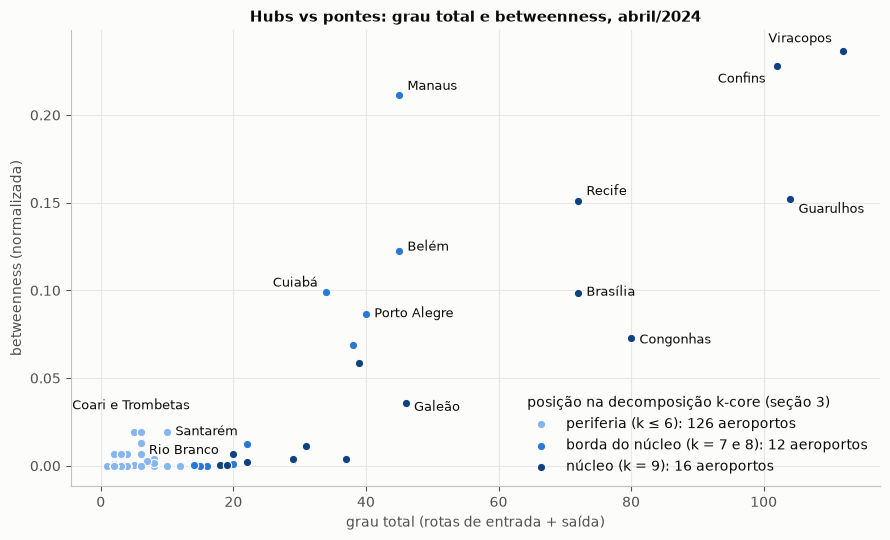

In [4]:
rotulos = {
    "SBKP": "Viracopos", "SBCF": "Confins", "SBGR": "Guarulhos", "SBRF": "Recife", "SBBR": "Brasília",
    "SBSP": "Congonhas", "SBEG": "Manaus", "SBBE": "Belém", "SBCY": "Cuiabá", "SBPA": "Porto Alegre",
    "SBGL": "Galeão", "SBSN": "Santarém", "SBRB": "Rio Branco", "SWKO": "Coari e Trombetas",
}
deslocamentos = {
    "SBKP": (-8, 6, "right"), "SBCF": (-8, -12, "right"), "SBGR": (6, -10, "left"), "SBRF": (6, 4, "left"),
    "SBBR": (6, -2, "left"), "SBSP": (6, -4, "left"), "SBEG": (6, 4, "left"), "SBBE": (6, 0, "left"),
    "SBCY": (-6, 4, "right"), "SBPA": (6, -2, "left"), "SBGL": (6, -6, "left"), "SBSN": (6, -2, "left"),
    "SBRB": (6, -8, "left"), "SWKO": (-2, 16, "center"),
}

# cor pela posição na decomposição k-core (detalhada na seção 3)
core = analise_kcore(G_ref)["core_number"]
grupos = [
    ("periferia (k ≤ 6)", core <= 6, "#86b6ef"),
    ("borda do núcleo (k = 7 e 8)", core.between(7, 8), "#2a78d6"),
    (f"núcleo (k = {core.max()})", core == core.max(), "#104281"),
]

fig, ax = plt.subplots(figsize=(9, 5.5))
for rotulo, filtro, cor in grupos:
    nos = core[filtro].index
    ax.scatter(df_topologia.loc[nos, "grau total"], df_topologia.loc[nos, "betweenness"],
               s=36, color=cor, edgecolor="#fcfcfb", linewidth=0.8, label=f"{rotulo}: {len(nos)} aeroportos")
for icao, texto in rotulos.items():
    dx, dy, ha = deslocamentos[icao]
    ax.annotate(texto, (df_topologia.loc[icao, "grau total"], df_topologia.loc[icao, "betweenness"]),
                xytext=(dx, dy), textcoords="offset points", ha=ha, fontsize=9, color="#0b0b0b")
ax.set(title="Hubs vs pontes: grau total e betweenness, abril/2024",
       xlabel="grau total (rotas de entrada + saída)", ylabel="betweenness (normalizada)")
ax.legend(frameon=False, loc="lower right", title="posição na decomposição k-core (seção 3)", alignment="left")
fig.tight_layout()
fig.savefig(PASTA_FIG / "02_grau_vs_betweenness.png", dpi=150)
plt.show()

- **No topo, hubs e pontes são quase os mesmos.** 9 dos 10 maiores em grau estão também entre os 10 maiores em betweenness. Pelo critério que definimos, **H2 não se confirma no topo do ranking**.
- **A ordem, porém, muda.** Manaus (Eduardo Gomes) é só o 8º em grau, mas é o **3º em betweenness**, à frente de Guarulhos. Cuiabá (Marechal Rondon) sobe de 14º para 7º e é o único que entra no top 10 de betweenness sem estar no de grau. São as portas de entrada da Amazônia e do Centro-Oeste: muitos menores caminhos para o Norte passam por elas.
- **Abaixo do topo, H2 se confirma.** Quatro aeroportos estão entre os 20 maiores em betweenness e fora dos 20 maiores em grau: **Coari (AM), Trombetas (PA), Santarém (PA) e Rio Branco (AC)**, com grau entre 5 e 10. São pontes regionais da Amazônia: ligam aeroportos ainda menores ao resto da malha e não aparecem entre os grandes em número de rotas.
- **O caso inverso também existe.** O Galeão é o 7º em grau, mas só o 13º em betweenness: é hub sem ser ponte. Uma explicação provável é que o Santos Dumont e os hubs de São Paulo e Belo Horizonte oferecem caminhos alternativos.
- **A cor de cada ponto mostra sua posição na decomposição k-core** (seção 3). Os quatro aeroportos que mais se destacam com betweenness alta para o grau que têm (Manaus, Belém, Cuiabá e Porto Alegre) estão todos na **borda do núcleo** (k = 7 e 8), e as pontes amazônicas estão na **periferia**. Já metade do núcleo (Natal, Salvador, Maceió, Porto Seguro, Goiânia, Vitória, João Pessoa e Uberlândia) tem grau entre 18 e 37 e betweenness quase zero: são aeroportos bem conectados, mas que não são passagem obrigatória para ninguém.
- **Conclusão parcial:** grau e betweenness concordam sobre quem são os grandes aeroportos, mas não sobre a ordem nem sobre a periferia. O impacto real de fechar uma dessas pontes será medido no ranking de aeroportos críticos.

Figura salva em `figures/02_grau_vs_betweenness.png`.

## 2. Outras centralidades: closeness e eigenvector (Sem. 4)

A **closeness** é o inverso da distância média de um aeroporto até todos os outros: quanto maior, mais perto do resto da malha. A **eigenvector** dá mais peso a quem está ligado a aeroportos que também são importantes. As duas são calculadas no grafo não dirigido (a justificativa está em `src/metricas.py`).

In [5]:
rankings = pd.DataFrame({
    medida: [nome_curto(G_ref, n) for n in df_topologia[medida].nlargest(10).index]
    for medida in ["grau total", "betweenness", "closeness", "eigenvector"]
}, index=range(1, 11))
rankings

,grau total,betweenness,closeness,eigenvector
1,Viracopos (SP),Viracopos (SP),Viracopos (SP),Guarulhos (SP)
2,Guarulhos (SP),Tancredo Neves (MG),Guarulhos (SP),Viracopos (SP)
3,Tancredo Neves (MG),Eduardo Gomes (AM),Brasília (DF),Tancredo Neves (MG)
4,Congonhas (SP),Guarulhos (SP),Tancredo Neves (MG),Brasília (DF)
5,Guararapes (PE),Guararapes (PE),Guararapes (PE),Congonhas (SP)
6,Brasília (DF),Val de Cans (PA),Galeão (RJ),Guararapes (PE)
7,Galeão (RJ),Marechal Rondon (MT),Val de Cans (PA),Galeão (RJ)
8,Val de Cans (PA),Brasília (DF),Congonhas (SP),Deputado Luís Eduardo Magalhães (BA)
9,Eduardo Gomes (AM),Salgado Filho (RS),Pinto Martins (CE),Pinto Martins (CE)
10,Salgado Filho (RS),Congonhas (SP),Eduardo Gomes (AM),Zumbi dos Palmares (AL)


- A **closeness acompanha o grau**: seus 10 primeiros são os mesmos do grau, trocando o Salgado Filho por Fortaleza (Pinto Martins).
- A **eigenvector favorece o núcleo e o Nordeste**: entram Salvador, Fortaleza e Maceió; saem Manaus, Belém e Porto Alegre. Os aeroportos do Nordeste ganham pontos por terem muitas rotas para os grandes hubs do Sudeste e do Distrito Federal.
- **Só a betweenness coloca Manaus e Cuiabá no topo.** Para identificar pontes, ela é a medida adequada. Closeness e eigenvector medem proximidade e prestígio, que andam junto com o grau.

## 3. Estrutura núcleo-periferia: k-core (Sem. 5)

A decomposição k-core remove repetidamente os aeroportos com menos de k vizinhos. O **core number** de um aeroporto é o maior k em que ele ainda sobrevive; o **k-shell** k reúne os aeroportos com core number exatamente k; a **degeneracy** é o maior k-core não vazio. O cálculo é feito no grafo não dirigido.

In [6]:
df_core = analise_kcore(G_ref)
df_core.insert(0, "aeroporto", [nome_curto(G_ref, n) for n in df_core.index])

max_core = df_core["core_number"].max()
nucleo = df_core[df_core["core_number"] == max_core]
print(f"k-core máximo (degeneracy): {max_core}")
print(f"aeroportos no {max_core}-core: {len(nucleo)}")
nucleo

k-core máximo (degeneracy): 9
aeroportos no 9-core: 16


,aeroporto,core_number
SBFZ,Pinto Martins (CE),9
SBKP,Viracopos (SP),9
SBGR,Guarulhos (SP),9
SBBR,Brasília (DF),9
SBGL,Galeão (RJ),9
SBCF,Tancredo Neves (MG),9
SBRF,Guararapes (PE),9
SBSG,Governador Aluizio Alves (RN),9
SBSV,Deputado Luís Eduardo Magalhães (BA),9
SBSP,Congonhas (SP),9


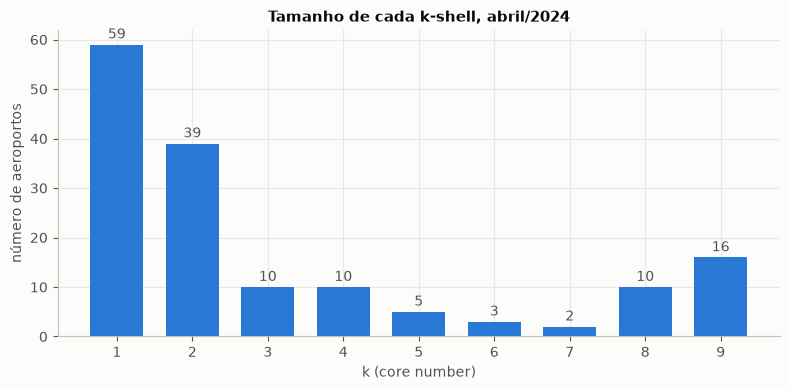

In [7]:
tamanho_shells = df_core["core_number"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(8, 4))
barras = ax.bar(tamanho_shells.index, tamanho_shells.values, color=COR_REF, width=0.7)
ax.bar_label(barras, padding=2, color="#52514e")
ax.set_xticks(tamanho_shells.index)
ax.set(title="Tamanho de cada k-shell, abril/2024", xlabel="k (core number)", ylabel="número de aeroportos")
fig.tight_layout()
fig.savefig(PASTA_FIG / "02_kshells.png", dpi=150)
plt.show()

In [8]:
# onde estão as pontes da seção 1 na decomposição em k-shells?
pontes = df_topologia.nsmallest(10, "posição betweenness").index.union(pontes_regionais.index)
df_topologia.loc[pontes, ["aeroporto", "posição betweenness"]].join(df_core["core_number"]).sort_values("posição betweenness")

,aeroporto,posição betweenness,core_number
SBKP,Viracopos (SP),1,9
SBCF,Tancredo Neves (MG),2,9
SBEG,Eduardo Gomes (AM),3,7
SBGR,Guarulhos (SP),4,9
SBRF,Guararapes (PE),5,9
SBBE,Val de Cans (PA),6,8
SBCY,Marechal Rondon (MT),7,8
SBBR,Brasília (DF),8,9
SBPA,Salgado Filho (RS),9,8
SBSP,Congonhas (SP),10,9


- A degeneracy é **9**: existe um núcleo de **16 aeroportos** em que cada um tem pelo menos 9 vizinhos dentro do próprio grupo. Ele reúne os grandes hubs do Sudeste e de Brasília e vários aeroportos do Nordeste e turísticos: Natal, Salvador, Recife, Fortaleza, Maceió, João Pessoa e Porto Seguro, além de Goiânia, Vitória e Uberlândia.
- A distribuição dos k-shells tem **forma de U**: 59 aeroportos (38%) no 1-shell e 39 no 2-shell, isto é, ligados a apenas 1 ou 2 vizinhos; poucos aeroportos nos níveis intermediários; e 26 aeroportos nos shells 8 e 9. Isso confirma a estrutura **núcleo-periferia** vista na matriz de adjacência do notebook 01 (subpergunta 1).
- **As pontes não estão no núcleo mais denso** (veja também a figura da seção 1, colorida por k-shell). Manaus (k = 7), Belém, Cuiabá e Porto Alegre (k = 8) ficam fora do 9-core, e as pontes regionais (Coari, Trombetas, Rio Branco, Santarém) estão nos shells 2 e 3. O núcleo é redundante: seus membros se ligam por muitos caminhos. As pontes ficam na **borda do núcleo**, ligando-o à periferia, e por isso têm betweenness alta sem pertencer a ele.
- Isso já esboça uma resposta para a pergunta principal: **o núcleo concentra os hubs, e as pontes ficam na sua borda**. Se o núcleo é redundante, fechar um hub pode ser compensado por outro; fechar uma ponte de borda pode não ter substituto.

Figura salva em `figures/02_kshells.png`.

## 4. Escalas: Natal e as capitais (Sem. 3 e 4)

O número de escalas é calculado por **BFS** (busca em largura), sem peso: escalas = voos no menor caminho menos 1. As 27 capitais e seus aeroportos seguem `docs/modelagem.md`. Para São Paulo e Rio de Janeiro, que têm dois aeroportos no modelo, vale o menor caminho entre eles.

In [9]:
df_natal = escalas_bfs_origem(G_ref, "SBSG")
print(f"aeroportos alcançáveis a partir de Natal: {len(df_natal)} de {G_ref.number_of_nodes() - 1}")
df_natal["escalas"].value_counts().sort_index().rename_axis("escalas").rename("aeroportos").to_frame()

aeroportos alcançáveis a partir de Natal: 153 de 153


,aeroportos
escalas,
0,16
1,94
2,38
3,4
4,1


In [10]:
mais_longe = df_natal[df_natal["escalas"] >= 3].copy()
mais_longe["aeroporto"] = [nome_curto(G_ref, n) for n in mais_longe["destino"]]
mais_longe["caminho"] = [" -> ".join(nome_curto(G_ref, a) for a in nx.shortest_path(G_ref, "SBSG", n))
                         for n in mais_longe["destino"]]
with pd.option_context("display.max_colwidth", None):
    display(mais_longe[["aeroporto", "escalas", "caminho"]])

,aeroporto,escalas,caminho
148,Brejo (PA),3,Governador Aluizio Alves (RN) -> Pinto Martins (CE) -> Eduardo Gomes (AM) -> Itaituba (PA) -> Brejo (PA)
149,Oriximiná (PA),3,Governador Aluizio Alves (RN) -> Pinto Martins (CE) -> Eduardo Gomes (AM) -> Trombetas (PA) -> Oriximiná (PA)
150,Santa Izabel do Rio Negro (AM),3,Governador Aluizio Alves (RN) -> Pinto Martins (CE) -> Eduardo Gomes (AM) -> Coari (AM) -> Santa Izabel do Rio Negro (AM)
151,Juína (MT),3,Governador Aluizio Alves (RN) -> Viracopos (SP) -> Marechal Rondon (MT) -> Aripuanã (MT) -> Juína (MT)
152,Monte Alegre (PA),4,Governador Aluizio Alves (RN) -> Pinto Martins (CE) -> Eduardo Gomes (AM) -> Trombetas (PA) -> Oriximiná (PA) -> Monte Alegre (PA)


In [11]:
escalas_cap = escalas_entre_capitais(G_ref, CAPITAIS)
valores = escalas_cap.stack().dropna()
print(f"pares de capitais (origem, destino): {len(valores)}; sem caminho: {escalas_cap.isna().sum().sum() - len(CAPITAIS)}")
print(valores.value_counts().sort_index().rename_axis("escalas").rename("pares").to_string())
print("\nescalas de Natal até as outras capitais:")
natal = escalas_cap.loc["Natal"].drop("Natal")
print("  voo direto:", sorted(natal[natal == 0].index))
print("  1 escala:  ", sorted(natal[natal == 1].index))

pares de capitais (origem, destino): 702; sem caminho: 0
escalas
0.0    249
1.0    453

escalas de Natal até as outras capitais:
  voo direto: ['Belo Horizonte', 'Belém', 'Brasília', 'Fortaleza', 'Recife', 'Rio de Janeiro', 'Salvador', 'São Paulo']
  1 escala:   ['Aracaju', 'Boa Vista', 'Campo Grande', 'Cuiabá', 'Curitiba', 'Florianópolis', 'Goiânia', 'João Pessoa', 'Macapá', 'Maceió', 'Manaus', 'Palmas', 'Porto Alegre', 'Porto Velho', 'Rio Branco', 'São Luís', 'Teresina', 'Vitória']


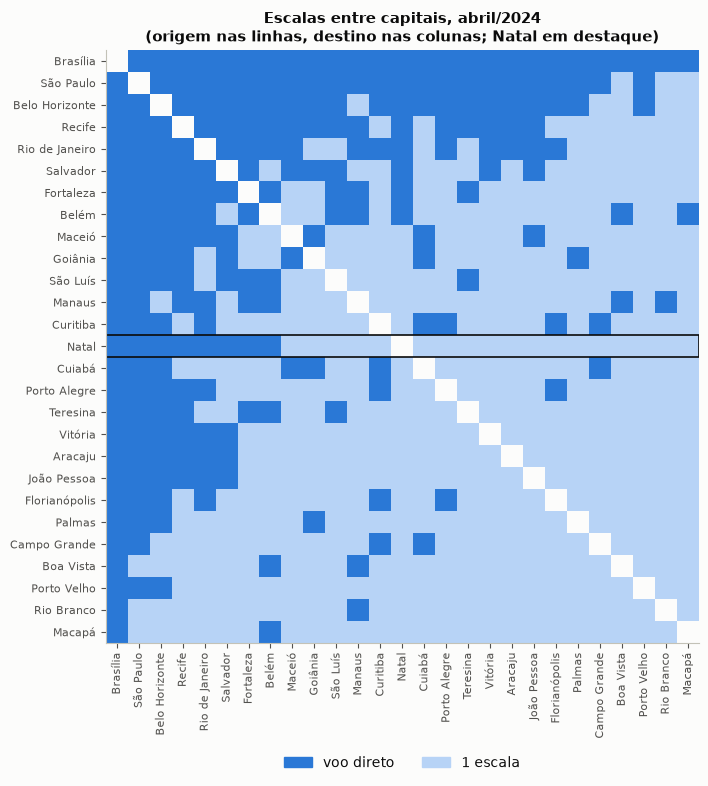

In [12]:
ordem = escalas_cap.mean(axis=1).sort_values().index
M = escalas_cap.loc[ordem, ordem]

from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch, Rectangle
fig, ax = plt.subplots(figsize=(8.5, 8))
ax.imshow(M.values, cmap=ListedColormap([COR_REF, COR_CLARA]), vmin=0, vmax=1, interpolation="nearest")
ax.grid(False)
ax.set_xticks(range(len(ordem)), ordem, rotation=90, fontsize=8)
ax.set_yticks(range(len(ordem)), ordem, fontsize=8)
i = list(ordem).index("Natal")
ax.add_patch(Rectangle((-0.5, i - 0.5), len(ordem), 1, fill=False, edgecolor="#0b0b0b", linewidth=1.2))
ax.legend(handles=[Patch(color=COR_REF, label="voo direto"), Patch(color=COR_CLARA, label="1 escala")],
          loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=2, frameon=False)
ax.set_title("Escalas entre capitais, abril/2024\n(origem nas linhas, destino nas colunas; Natal em destaque)")
fig.tight_layout()
fig.savefig(PASTA_FIG / "02_escalas_capitais.png", dpi=150)
plt.show()

- A partir de Natal, os 153 aeroportos são alcançáveis: 16 com voo direto, 94 com 1 escala, 38 com 2, 4 com 3 e 1 com 4 escalas (Monte Alegre, PA).
- Os destinos mais distantes ficam no Pará, no Amazonas e no Mato Grosso, e os caminhos passam por **Fortaleza e Manaus** (ou Viracopos e Cuiabá). As pontes da seção 1 aparecem aqui na prática.
- Entre capitais, **nenhum par precisa de mais de 1 escala**: dos 702 pares (origem, destino), 249 têm voo direto e 453 precisam de uma escala.
- **Brasília tem voo direto para todas as outras 26 capitais** (primeira linha da figura). São Paulo e Belo Horizonte vêm logo depois.
- As capitais do Norte dependem de poucos aeroportos: **Macapá e Rio Branco têm voo direto para só 2 capitais**, e Boa Vista e Porto Velho, para 3. Brasília está entre elas em todos os casos.
- **Natal** tem voo direto para 8 capitais (Belo Horizonte, Belém, Brasília, Fortaleza, Recife, Rio de Janeiro, Salvador e São Paulo) e chega às outras 18 com uma escala.
- **Implicação:** como a linha de base é tão curta, qualquer fechamento que aumente escalas entre capitais aparece com clareza. E como Brasília liga todas as capitais diretamente, ela é forte candidata ao maior aumento de escalas entre capitais, o que será testado no ranking de aeroportos críticos.

Figura salva em `figures/02_escalas_capitais.png`.

## 5. Linha de base: eficiência global (Sem. 4)

A eficiência global é a média de 1/d entre todos os pares de aeroportos, com d em número de voos; pares sem caminho contam 0. Vai de 0 a 1, e 1 significaria voo direto entre todos os pares. Como a rede é dirigida, a média é feita sobre os n(n - 1) pares ordenados.

In [13]:
G_pos = carregar_grafo(raiz / "data" / "processed" / "rede_pos_fechamento.graphml")
print(f"eficiência global, referência (abril):          {eficiencia_global_dirigida(G_ref):.4f}")
print(f"eficiência global, pós-fechamento (04/05 a 30/06): {eficiencia_global_dirigida(G_pos):.4f}")

eficiência global, referência (abril):          0.3909
eficiência global, pós-fechamento (04/05 a 30/06): 0.3946


- A eficiência da malha de abril é **0,391**.
- A malha pós-fechamento tem eficiência um pouco maior (0,395), mesmo sem o Salgado Filho. Isso **não** quer dizer que o fechamento melhorou a malha: as duas redes têm conjuntos de aeroportos diferentes, e a malha real se reorganizou em maio e junho. A comparação justa entre o cenário simulado e o real fica para o notebook de POA (H4).
- Nas simulações de fechamento, a eficiência será normalizada pelo número de aeroportos da rede original, para que remover aeroportos não "melhore" a medida artificialmente.

## Resumo

- **H2, resultado misto:** no topo, hubs e pontes são quase os mesmos (9 de 10 em comum), mas Manaus e Cuiabá sobem muito em betweenness, e aeroportos amazônicos de grau 5 a 10 (Coari, Trombetas, Santarém, Rio Branco) aparecem como pontes regionais.
- **Núcleo-periferia confirmado:** degeneracy 9, um núcleo de 16 aeroportos e 98 aeroportos (64%) nos shells 1 e 2. As pontes ficam na borda do núcleo, não dentro dele.
- **Escalas curtas:** todas as capitais se ligam com no máximo 1 escala, e Brasília tem voo direto para as outras 26.
- **Eficiência global de 0,391** na malha de referência.

**Próximos passos:** simular fechamentos (H1 e H3) e montar o ranking de aeroportos críticos, testando em especial Brasília (escalas entre capitais) e as pontes amazônicas (desconexão).